# 03 - Fine-tuning MobileNetV3-Small, analisis kesalahan, dan kontrol ukuran
Urutan: (1) sel `Sel 1` memuat data dan melatih seed 0-4, sel berikutnya seed 5-9 dan uji Wilcoxon terhadap Logistic Regression dari notebook 02;
(2) sel `Sel Setup` memuat ulang data dan fungsi (dipakai bila sesi Colab baru); (3) sel analisis: tabel per kelas, AUC metadata berkas (0,934),
contoh prediksi, kontrol ukuran/ketajaman (3 seed).

Pelatihan: 3 epoch hanya kepala klasifikasi (lr 1e-3), lalu 8 epoch seluruh jaringan (lr 1e-4), AdamW, cosine, augmentasi flip dan kecerahan/kontras.
Titik terbaik dipilih dari AUC validasi, ambang dari EER validasi. Sel awal yang gagal membaca arsip (jalur Drive kosong) dihapus; sisanya tidak diubah.

In [ ]:
# ===== Sel 1: muat data dan cache gambar 224x224 =====
import numpy as np, pandas as pd, torch, torch.nn as nn, torchvision, os, time
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score, roc_curve
from google.colab import drive; drive.mount('/content/drive')

WORK = '/content/drive/MyDrive/Dataset_CelebA-Spoof/work'
d = np.load(f'{WORK}/features.npz', allow_pickle=True)
idx = pd.read_csv(f'{WORK}/file_index_clean.csv')
keep = d['ok'] == 1
paths, y, subj = idx.path.values[keep], d['y'][keep], d['subject'][keep]
assert os.path.exists(paths[0]), 'Data hilang: jalankan ulang sel ekstraksi arsip dulu'

def load(p): return np.asarray(Image.open(p).convert('RGB').resize((224, 224)), dtype=np.uint8)
with ThreadPoolExecutor(4) as ex: X = np.stack(list(ex.map(load, paths)))
print(X.shape, round(X.nbytes / 1e9, 2), 'GB')

# ===== Sel 2: fungsi pendukung (sama dengan notebook 02) =====
subjects = np.unique(subj)
def split_by_subject(seed):
    ids = np.random.RandomState(seed).permutation(subjects); n = len(ids)
    trs, vas = ids[:int(.70*n)], ids[int(.70*n):int(.85*n)]
    tr_, va_ = np.isin(subj, trs), np.isin(subj, vas)
    return tr_, va_, ~(tr_ | va_)
def rates(yy, s, t):
    pred = (s >= t).astype(int)
    a = ((pred == 0) & (yy == 1)).sum() / max((yy == 1).sum(), 1)
    b = ((pred == 1) & (yy == 0)).sum() / max((yy == 0).sum(), 1)
    return a, b, (a + b) / 2
def eer_threshold(yy, s):
    fpr, tpr, thr = roc_curve(yy, s); return thr[np.nanargmin(np.abs(fpr - (1 - tpr)))]

dev = 'cuda'; Xt = torch.from_numpy(X)
mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
def prep(xb, train):
    xb = xb.to(dev).permute(0, 3, 1, 2).float() / 255.
    if train:
        n = xb.shape[0]
        xb = torch.where((torch.rand(n, device=dev) < .5).view(-1, 1, 1, 1), xb.flip(3), xb)
        c = 1 + (torch.rand(n, 1, 1, 1, device=dev) - .5) * .3
        b = (torch.rand(n, 1, 1, 1, device=dev) - .5) * .3
        xb = ((xb - .5) * c + .5 + b).clamp(0, 1)
    return (xb - mean) / std
@torch.no_grad()
def scores(m, ids, bs=256):
    m.eval(); out = []
    for i in range(0, len(ids), bs):
        out.append(torch.sigmoid(m(prep(Xt[torch.as_tensor(ids[i:i+bs])], False)).squeeze(1)).float().cpu())
    return torch.cat(out).numpy()

# ===== Sel 3: fine-tuning MobileNetV3-Small =====
def train_eval(seed, ep_head=3, ep_full=8, bs=64):
    tr_, va_, te_ = split_by_subject(seed)
    itr, iva, ite = [np.where(m_)[0] for m_ in (tr_, va_, te_)]
    torch.manual_seed(seed); np.random.seed(seed)
    m = torchvision.models.mobilenet_v3_small(weights='DEFAULT')
    m.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(576, 1)); m = m.to(dev)
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((y[itr] == 0).sum() / (y[itr] == 1).sum(), device=dev, dtype=torch.float32))

    def stage(epochs, lr, freeze):
        for p in m.features.parameters(): p.requires_grad = not freeze
        params = [p for p in m.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * (len(itr) // bs))
        best = (-1, None)
        for e in range(epochs):
            m.train()
            if freeze: m.features.eval()
            perm = np.random.permutation(itr)
            for i in range(0, len(perm) - bs + 1, bs):
                b = perm[i:i+bs]
                loss = crit(m(prep(Xt[torch.as_tensor(b)], True)).squeeze(1),
                            torch.as_tensor(y[b], dtype=torch.float32, device=dev))
                opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            auc = roc_auc_score(y[iva], scores(m, iva))
            if auc > best[0]: best = (auc, {k: v.clone() for k, v in m.state_dict().items()})
        m.load_state_dict(best[1]); return best[0]

    a1 = stage(ep_head, 1e-3, True); a2 = stage(ep_full, 1e-4, False)
    t = eer_threshold(y[iva], scores(m, iva))           # ambang dari VALIDASI
    s_te = scores(m, ite)
    a, b, h = rates(y[ite], s_te, t)
    return dict(seed=seed, AUC=roc_auc_score(y[ite], s_te), APCER=a, BPCER=b, HTER=h, val_auc=a2)

rows = []
for seed in range(5):                       # ganti ke range(10) jika waktu cukup
    t0 = time.time(); r = train_eval(seed); rows.append(r)
    print(seed, {k: round(v, 3) for k, v in r.items()}, f'{time.time()-t0:.0f}s')
FT = pd.DataFrame(rows); FT.to_csv(f'{WORK}/results_finetune.csv', index=False)

# ===== Sel 4: bandingkan dengan LR pada seed yang sama =====
R = pd.read_csv(f'{WORK}/results_repeated.csv')
ref = R[(R['mode'] == 'default') & (R.seed.isin(FT.seed))].groupby('fitur')[['AUC', 'APCER', 'BPCER', 'HTER']].mean()
print(ref.round(3)); print('Fine-tune MobileNetV3:'); print(FT[['AUC', 'APCER', 'BPCER', 'HTER']].agg(['mean', 'std']).round(3))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(8511, 224, 224, 3) 1.28 GB
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 127MB/s]


0 {'seed': 0, 'AUC': np.float64(0.999), 'APCER': np.float64(0.007), 'BPCER': np.float64(0.019), 'HTER': np.float64(0.013), 'val_auc': np.float64(0.999)} 82s
1 {'seed': 1, 'AUC': np.float64(0.999), 'APCER': np.float64(0.0), 'BPCER': np.float64(0.029), 'HTER': np.float64(0.014), 'val_auc': np.float64(0.998)} 72s
2 {'seed': 2, 'AUC': np.float64(0.999), 'APCER': np.float64(0.004), 'BPCER': np.float64(0.041), 'HTER': np.float64(0.023), 'val_auc': np.float64(0.998)} 74s
3 {'seed': 3, 'AUC': np.float64(0.994), 'APCER': np.float64(0.052), 'BPCER': np.float64(0.026), 'HTER': np.float64(0.039), 'val_auc': np.float64(0.999)} 79s
4 {'seed': 4, 'AUC': np.float64(1.0), 'APCER': np.float64(0.008), 'BPCER': np.float64(0.01), 'HTER': np.float64(0.009), 'val_auc': np.float64(0.998)} 85s
            AUC  APCER  BPCER   HTER
fitur                               
CNN       0.944  0.138  0.095  0.116
CNN+Frek  0.962  0.127  0.084  0.105
Fine-tune MobileNetV3:
        AUC  APCER  BPCER   HTER
mean  0.998  0.0

In [ ]:
rows2 = []
for seed in range(5, 10):
    t0 = time.time(); r = train_eval(seed); rows2.append(r)
    print(seed, {k: round(float(v), 3) for k, v in r.items()}, f'{time.time()-t0:.0f}s')
FT = pd.concat([FT, pd.DataFrame(rows2)], ignore_index=True)
FT.to_csv(f'{WORK}/results_finetune.csv', index=False)

from scipy.stats import wilcoxon
R = pd.read_csv(f'{WORK}/results_repeated.csv'); R = R[R['mode'] == 'default']
f = FT.set_index('seed').HTER.sort_index()
for fitur in ['CNN', 'CNN+Frek']:
    p = R[R.fitur == fitur].set_index('seed').HTER.sort_index()
    print(f'Fine-tune vs LR {fitur}: HTER {f.mean():.3f}±{f.std():.3f} vs {p.mean():.3f}±{p.std():.3f} | selisih {(p-f).mean():.3f} | Wilcoxon p={wilcoxon(p, f).pvalue:.4f}')
print(FT[['AUC', 'APCER', 'BPCER', 'HTER']].agg(['mean', 'std']).round(3))

5 {'seed': 5.0, 'AUC': 0.999, 'APCER': 0.0, 'BPCER': 0.059, 'HTER': 0.029, 'val_auc': 0.995} 90s
6 {'seed': 6.0, 'AUC': 0.996, 'APCER': 0.046, 'BPCER': 0.018, 'HTER': 0.032, 'val_auc': 0.999} 82s
7 {'seed': 7.0, 'AUC': 0.999, 'APCER': 0.06, 'BPCER': 0.007, 'HTER': 0.034, 'val_auc': 1.0} 78s
8 {'seed': 8.0, 'AUC': 0.999, 'APCER': 0.001, 'BPCER': 0.045, 'HTER': 0.023, 'val_auc': 0.994} 82s
9 {'seed': 9.0, 'AUC': 0.998, 'APCER': 0.011, 'BPCER': 0.032, 'HTER': 0.021, 'val_auc': 0.991} 80s
Fine-tune vs LR CNN: HTER 0.024±0.010 vs 0.101±0.042 | selisih 0.077 | Wilcoxon p=0.0020
Fine-tune vs LR CNN+Frek: HTER 0.024±0.010 vs 0.082±0.042 | selisih 0.059 | Wilcoxon p=0.0020
        AUC  APCER  BPCER   HTER
mean  0.998  0.019  0.028  0.024
std   0.002  0.024  0.016  0.010


In [4]:
# ===== Sel Setup: mount, ekstraksi (jika perlu), muat data, fungsi pendukung =====
!apt-get -qq update && apt-get -qq install -y libarchive-tools
import subprocess, glob, os, time
import numpy as np, pandas as pd, torch, torch.nn as nn, torchvision
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score, roc_curve
from google.colab import drive; drive.mount('/content/drive')

WORK = '/content/drive/MyDrive/Dataset_CelebA-Spoof/work'
d = np.load(f'{WORK}/features.npz', allow_pickle=True)
idx = pd.read_csv(f'{WORK}/file_index_clean.csv')
keep = d['ok'] == 1
paths, y, subj = idx.path.values[keep], d['y'][keep], d['subject'][keep]

# ekstraksi arsip bila folder sementara hilang
if not os.path.exists(paths[0]):
    parts = sorted(glob.glob('/content/drive/MyDrive/Dataset_CelebA-Spoof/*zip.00[1-4]'))
    print(parts); os.makedirs('/content/celeba', exist_ok=True)
    p = subprocess.Popen(['bsdtar', '-xf', '-'], stdin=subprocess.PIPE, stderr=subprocess.PIPE, cwd='/content/celeba')
    try:
        for part in parts:
            with open(part, 'rb') as fh:
                while chunk := fh.read(1 << 24): p.stdin.write(chunk)
        p.stdin.close()
    except BrokenPipeError: pass
    print(p.stderr.read().decode()[-300:]); p.wait()
assert os.path.exists(paths[0]), 'Ekstraksi gagal'

# cache gambar 224x224 (disimpan ke Drive supaya sesi berikutnya cepat)
CACHE = f'{WORK}/X224.npy'
if os.path.exists(CACHE): X = np.load(CACHE)
else:
    def load(p): return np.asarray(Image.open(p).convert('RGB').resize((224, 224)), dtype=np.uint8)
    with ThreadPoolExecutor(4) as ex: X = np.stack(list(ex.map(load, paths)))
    np.save(CACHE, X)
assert len(X) == len(y); print(X.shape, round(X.nbytes / 1e9, 2), 'GB')

subjects = np.unique(subj)
def split_by_subject(seed):
    ids = np.random.RandomState(seed).permutation(subjects); n = len(ids)
    trs, vas = ids[:int(.70*n)], ids[int(.70*n):int(.85*n)]
    tr_, va_ = np.isin(subj, trs), np.isin(subj, vas)
    return tr_, va_, ~(tr_ | va_)
def rates(yy, s, t):
    pred = (s >= t).astype(int)
    a = ((pred == 0) & (yy == 1)).sum() / max((yy == 1).sum(), 1)
    b = ((pred == 1) & (yy == 0)).sum() / max((yy == 0).sum(), 1)
    return a, b, (a + b) / 2
def eer_threshold(yy, s):
    fpr, tpr, thr = roc_curve(yy, s); return thr[np.nanargmin(np.abs(fpr - (1 - tpr)))]

dev = 'cuda'; Xt = torch.from_numpy(X)
mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
def prep(xb, train):
    xb = xb.to(dev).permute(0, 3, 1, 2).float() / 255.
    if train:
        n = xb.shape[0]
        xb = torch.where((torch.rand(n, device=dev) < .5).view(-1, 1, 1, 1), xb.flip(3), xb)
        c = 1 + (torch.rand(n, 1, 1, 1, device=dev) - .5) * .3
        b = (torch.rand(n, 1, 1, 1, device=dev) - .5) * .3
        xb = ((xb - .5) * c + .5 + b).clamp(0, 1)
    return (xb - mean) / std
@torch.no_grad()
def scores(m, ids, bs=256):
    m.eval(); out = []
    for i in range(0, len(ids), bs):
        out.append(torch.sigmoid(m(prep(Xt[torch.as_tensor(ids[i:i+bs])], False)).squeeze(1)).float().cpu())
    return torch.cat(out).numpy()
print('siap')

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Mounted at /content/drive
['/content/drive/MyDrive/Dataset_CelebA-Spoof/Salinan CelebA_Spoof.zip.001', '/content/drive/MyDrive/Dataset_CelebA-Spoof/Salinan CelebA_Spoof.zip.002', '/content/drive/MyDrive/Dataset_CelebA-Spoof/Salinan CelebA_Spoof.zip.003', '/content/drive/MyDrive/Dataset_CelebA-Spoof/Salinan CelebA_Spoof.zip.004']
CelebA_Spoof/Data/test/5212/spoof/516352.png: ZIP decompression failed (-5): Unknown error -1
bsdtar: Error exit delayed from previous errors.

(8511, 224, 224, 3) 1.28 GB
siap


In [5]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
FIG = f'{WORK}/figures'; os.makedirs(FIG, exist_ok=True)

df = idx[keep].reset_index(drop=True)
df['y'] = y; df['subject'] = subj
sz = []
for p in df.path:
    with Image.open(p) as im: sz.append(im.size)
df['w'] = [s[0] for s in sz]; df['h'] = [s[1] for s in sz]
df['bytes'] = df.path.map(os.path.getsize); df['mp'] = df.w * df.h / 1e6

g = df.groupby('label')
tab = pd.DataFrame({
  'citra': g.size(), 'persen': (g.size() / len(df) * 100).round(1),
  'subjek': g.subject.nunique(),
  'citra_per_subjek_median': g.subject.apply(lambda s: s.value_counts().median()),
  'lebar_median': g.w.median(), 'tinggi_median': g.h.median(),
  'megapiksel_median': g.mp.median().round(3), 'ukuran_KB_median': (g.bytes.median() / 1024).round(0)})
print(tab.T.to_string()); tab.to_csv(f'{WORK}/table_per_class.csv')
print('subjek dengan kedua kelas:', (df.groupby('subject').label.nunique() == 2).sum(), 'dari', df.subject.nunique())

# jalan pintas: metadata file saja (tanpa melihat wajah), split subjek sama dengan eksperimen
F = np.c_[df.w, df.h, np.log(df.bytes), df.bytes / (df.w * df.h)]
aucs = []
for seed in range(10):
    tr_, va_, te_ = split_by_subject(seed)
    if len(np.unique(y[te_])) < 2: continue
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced'))
    clf.fit(F[tr_], y[tr_]); aucs.append(roc_auc_score(y[te_], clf.predict_proba(F[te_])[:, 1]))
print('AUC metadata saja:', np.round(aucs, 3), '| rata-rata', round(np.mean(aucs), 3))

label                       live     spoof
citra                    1686.00  6825.000
persen                     19.80    80.200
subjek                     77.00    79.000
citra_per_subjek_median    24.00    58.000
lebar_median              404.00   480.000
tinggi_median             500.00   640.000
megapiksel_median           0.21     0.307
ukuran_KB_median          317.00   442.000
subjek dengan kedua kelas: 77 dari 79
AUC metadata saja: [0.958 0.972 0.903 0.937 0.958 0.94  0.944 0.962 0.868 0.903] | rata-rata 0.934


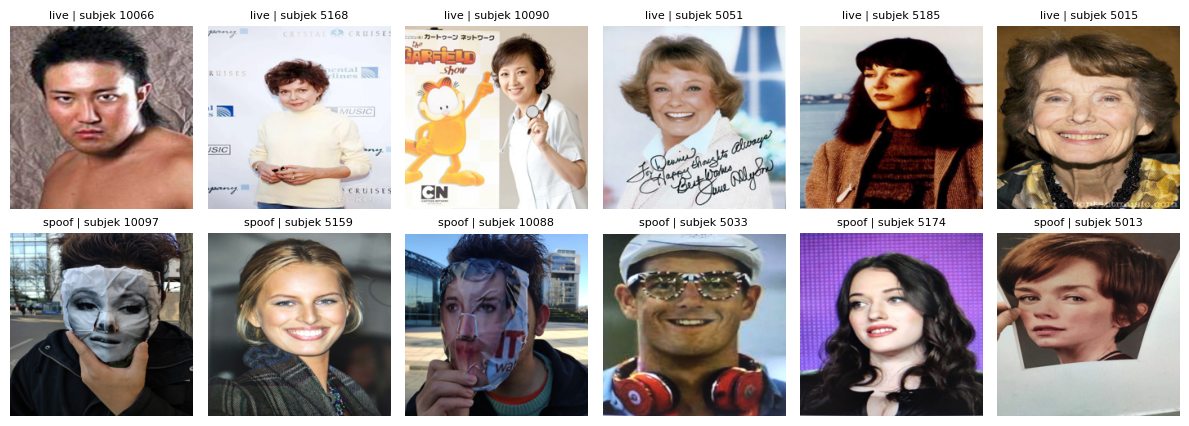

In [6]:
rs = np.random.RandomState(7)
fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
for r, lab in enumerate(['live', 'spoof']):
    sub = df[df.label == lab].groupby('subject').sample(1, random_state=7)
    for c, (_, row) in enumerate(sub.sample(6, random_state=7).iterrows()):
        ax[r, c].imshow(Image.open(row.path).convert('RGB').resize((224, 224)))
        ax[r, c].set_title(f'{lab} | subjek {row.subject}', fontsize=8); ax[r, c].axis('off')
plt.tight_layout(); plt.savefig(f'{FIG}/fig_samples_class.png', dpi=200); plt.show()

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 53.8MB/s]


ambang=0.109 | test: live=269, spoof=888, subjek=12
kelas  jumlah  benar  salah  tingkat_benar
 live     269    264      5          0.981
spoof     888    883      5          0.994
APCER, BPCER, HTER = [np.float64(0.006), np.float64(0.019), np.float64(0.012)] | AUC = 0.999


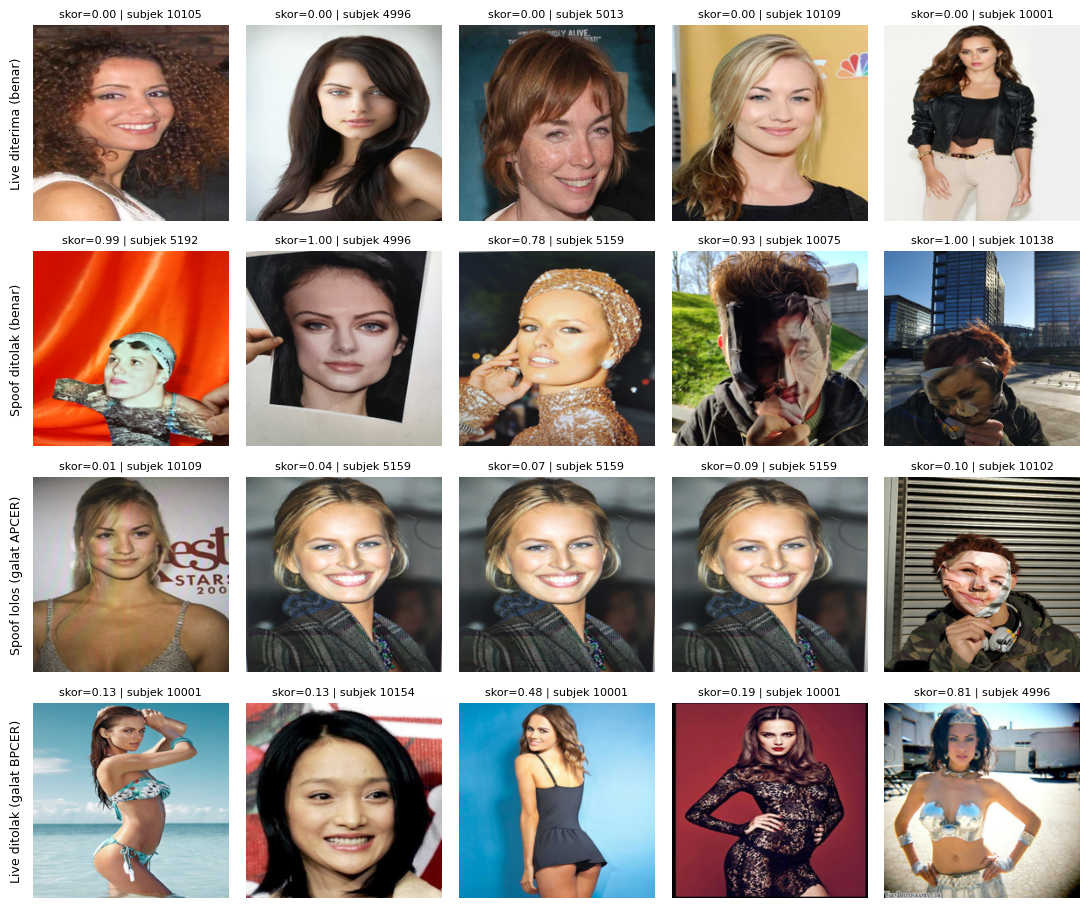

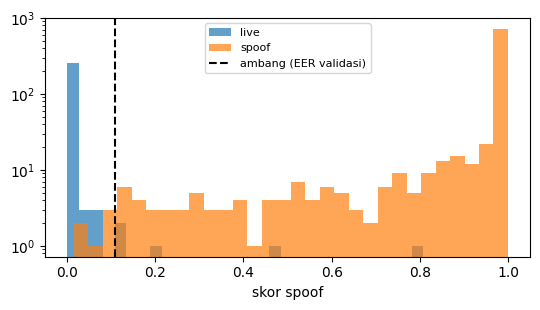

In [7]:
def train_model(seed, ep_head=3, ep_full=8, bs=64):
    tr_, va_, te_ = split_by_subject(seed)
    itr, iva, ite = [np.where(m_)[0] for m_ in (tr_, va_, te_)]
    torch.manual_seed(seed); np.random.seed(seed)
    m = torchvision.models.mobilenet_v3_small(weights='DEFAULT')
    m.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(576, 1)); m = m.to(dev)
    crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((y[itr] == 0).sum() / (y[itr] == 1).sum(), device=dev, dtype=torch.float32))
    def stage(epochs, lr, freeze):
        for p in m.features.parameters(): p.requires_grad = not freeze
        opt = torch.optim.AdamW([p for p in m.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * (len(itr) // bs))
        best = (-1, None)
        for e in range(epochs):
            m.train()
            if freeze: m.features.eval()
            perm = np.random.permutation(itr)
            for i in range(0, len(perm) - bs + 1, bs):
                b = perm[i:i+bs]
                loss = crit(m(prep(Xt[torch.as_tensor(b)], True)).squeeze(1), torch.as_tensor(y[b], dtype=torch.float32, device=dev))
                opt.zero_grad(); loss.backward(); opt.step(); sched.step()
            auc = roc_auc_score(y[iva], scores(m, iva))
            if auc > best[0]: best = (auc, {k: v.clone() for k, v in m.state_dict().items()})
        m.load_state_dict(best[1])
    stage(ep_head, 1e-3, True); stage(ep_full, 1e-4, False)
    return m, eer_threshold(y[iva], scores(m, iva)), ite

m, t, ite = train_model(0)
s = scores(m, ite); yt = y[ite]; pred = (s >= t).astype(int)
live_ok = (pred == 0) & (yt == 0); live_bad = (pred == 1) & (yt == 0)   # live ditolak (galat BPCER)
spf_ok = (pred == 1) & (yt == 1);  spf_bad = (pred == 0) & (yt == 1)    # spoof lolos (galat APCER)
print(f'ambang={t:.3f} | test: live={int((yt==0).sum())}, spoof={int((yt==1).sum())}, subjek={len(np.unique(subj[ite]))}')
print(pd.DataFrame({'kelas': ['live', 'spoof'], 'jumlah': [(yt == 0).sum(), (yt == 1).sum()],
      'benar': [live_ok.sum(), spf_ok.sum()], 'salah': [live_bad.sum(), spf_bad.sum()],
      'tingkat_benar': [live_ok.sum() / (yt == 0).sum(), spf_ok.sum() / (yt == 1).sum()]}).round(3).to_string(index=False))
print('APCER, BPCER, HTER =', [round(v, 3) for v in rates(yt, s, t)], '| AUC =', round(roc_auc_score(yt, s), 3))
pd.DataFrame({'path': paths[ite], 'subject': subj[ite], 'y': yt, 'score': s, 'pred': pred}).to_csv(f'{WORK}/pred_seed0.csv', index=False)

rows = [('Live diterima (benar)', live_ok), ('Spoof ditolak (benar)', spf_ok), ('Spoof lolos (galat APCER)', spf_bad), ('Live ditolak (galat BPCER)', live_bad)]
fig, ax = plt.subplots(4, 5, figsize=(11, 9.2)); rs = np.random.RandomState(3)
for r, (name, mask) in enumerate(rows):
    sel = rs.choice(np.where(mask)[0], min(5, mask.sum()), replace=False) if mask.sum() else []
    for c in range(5):
        ax[r, c].axis('off')
        if c < len(sel):
            j = sel[c]; ax[r, c].imshow(X[ite[j]]); ax[r, c].set_title(f'skor={s[j]:.2f} | subjek {subj[ite[j]]}', fontsize=8)
    ax[r, 0].text(-0.05, 0.5, name, transform=ax[r, 0].transAxes, rotation=90, va='center', ha='right', fontsize=9)
plt.tight_layout(); plt.savefig(f'{FIG}/fig_pred_examples.png', dpi=200); plt.show()

plt.figure(figsize=(5.5, 3.2))
plt.hist(s[yt == 0], bins=30, alpha=.7, label='live'); plt.hist(s[yt == 1], bins=30, alpha=.7, label='spoof')
plt.axvline(t, color='k', ls='--', label='ambang (EER validasi)'); plt.yscale('log'); plt.xlabel('skor spoof'); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{FIG}/fig_score_hist.png', dpi=200); plt.show()

In [9]:
te = df.iloc[ite].copy(); te['score'] = s; te['pred'] = pred
te['mp_bin'] = pd.qcut(df.mp.rank(method='first'), 4, labels=False).iloc[ite].values
for b in range(4):
    sub = te[te.mp_bin == b]; nl, ns = (sub.y == 0).sum(), (sub.y == 1).sum()
    if nl >= 10 and ns >= 10:
        print(f'bin {b}: live={nl} spoof={ns} | AUC={roc_auc_score(sub.y, sub.score):.3f}')
    else: print(f'bin {b}: live={nl} spoof={ns} (terlalu sedikit)')
print(te[te.pred != te.y].groupby(['label', 'subject']).size())

bin 0: live=171 spoof=144 | AUC=1.000
bin 1: live=5 spoof=321 (terlalu sedikit)
bin 2: live=0 spoof=247 (terlalu sedikit)
bin 3: live=93 spoof=176 | AUC=0.991
label  subject
live   4996       1
       10001      3
       10154      1
spoof  5159       3
       10102      1
       10109      1
dtype: int64


In [10]:
def load_ctrl(p):
    im = Image.open(p).convert('RGB'); w, h = im.size; k = min(w, h)
    im = im.crop(((w - k) // 2, (h - k) // 2, (w - k) // 2 + k, (h - k) // 2 + k))
    return np.asarray(im.resize((112, 112), Image.LANCZOS).resize((224, 224), Image.BILINEAR), dtype=np.uint8)
with ThreadPoolExecutor(4) as ex: X_ctrl = np.stack(list(ex.map(load_ctrl, paths)))

Xt_orig = Xt; Xt = torch.from_numpy(X_ctrl); res = []
for seed in range(3):
    m2, t2, ite2 = train_model(seed); s2 = scores(m2, ite2); yt2 = y[ite2]
    a, b, h = rates(yt2, s2, t2)
    res.append(dict(seed=seed, AUC=roc_auc_score(yt2, s2), APCER=a, BPCER=b, HTER=h)); print(res[-1])
Xt = Xt_orig
pd.DataFrame(res).to_csv(f'{WORK}/results_control.csv', index=False); print(pd.DataFrame(res).mean().round(3))

{'seed': 0, 'AUC': np.float64(0.9978817107069896), 'APCER': np.float64(0.02252252252252252), 'BPCER': np.float64(0.022304832713754646), 'HTER': np.float64(0.022413677618138582)}
{'seed': 1, 'AUC': np.float64(0.9949652575121798), 'APCER': np.float64(0.007685738684884714), 'BPCER': np.float64(0.07913669064748201), 'HTER': np.float64(0.04341121466618336)}
{'seed': 2, 'AUC': np.float64(0.9898037918871252), 'APCER': np.float64(0.024553571428571428), 'BPCER': np.float64(0.09053497942386832), 'HTER': np.float64(0.05754427542621987)}
seed     1.000
AUC      0.994
APCER    0.018
BPCER    0.064
HTER     0.041
dtype: float64
